<a href="https://colab.research.google.com/github/nsonyiwa-rose-nabakka/AI-STEM-shortcourse/blob/main/Week5_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Week 5 Assignment: Building your first supervised machine learning model
Project: El Nino prediction


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix)

url = 'https://raw.githubusercontent.com/ahuang11/oni/master/oni.csv'
df = pd.read_csv(url)
print(df.shape)
df.head()

(919, 8)


,season,year,sst_c,anom_c,threshold,cumulative,ntotal,oni
0,DJF,1950,25.01,-1.32,below,1,13,la_nina
1,JFM,1950,25.36,-1.20,below,2,13,la_nina
2,FMA,1950,25.88,-1.12,below,3,13,la_nina
3,MAM,1950,26.24,-1.08,below,4,13,la_nina
4,AMJ,1950,26.35,-1.10,below,5,13,la_nina


In [3]:
df.info()
print (df.isna().sum())
df['oni'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 919 entries, 0 to 918
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      919 non-null    object 
 1   year        919 non-null    int64  
 2   sst_c       919 non-null    float64
 3   anom_c      919 non-null    float64
 4   threshold   919 non-null    object 
 5   cumulative  919 non-null    int64  
 6   ntotal      919 non-null    int64  
 7   oni         919 non-null    object 
dtypes: float64(2), int64(3), object(3)
memory usage: 57.6+ KB
season        0
year          0
sst_c         0
anom_c        0
threshold     0
cumulative    0
ntotal        0
oni           0
dtype: int64


,count
oni,
neutral,483
la_nina,221
el_nino,215


Data preparation and feature engineering


*   Sort the rows by time (year, then season order)
*   Add lagged anomaly features (the anomaly 1,2 and 3 seasons ago) and the change in anomaly. These show whether the ocean is warming and cooling.
*   Encode the season as a number (1 to 2 ) so the model can learn seasonal patterns
*   Shift the target one row forward, so each row predicts the next season's phase.
*   Drop rows with missing values (created by lagging and shifting)








In [9]:
season_order = ['DJF', 'JFM', 'FMA', 'MAM', 'AMJ', 'MJJ', 'JJA', 'JAS', 'ASO', 'SON', 'OND', 'NDJ']
df['season_num'] = df['season'].map({s: i+1 for i, s in enumerate(season_order)})
df = df.sort_values(['year', 'season_num']).reset_index(drop=True)

for lag in [1, 2, 3]:
    df[f'anom_lag{lag}'] = df['anom_c'].shift(lag)
df['anom_change'] = df['anom_c'] - df['anom_lag1']

#Target: the ENSO phase of the NEXT season
df['target'] = df['oni'].shift(-1)

data = df.dropna(subset=['anom_lag3', 'target']).copy()
data[['year', 'season', 'anom_c', 'anom_lag1', 'anom_change', 'oni', 'target']].head()

,year,season,anom_c,anom_lag1,anom_change,oni,target
3,1950,MAM,-1.08,-1.12,0.04,la_nina,la_nina
4,1950,AMJ,-1.10,-1.08,-0.02,la_nina,la_nina
5,1950,MJJ,-0.90,-1.10,0.20,la_nina,la_nina
6,1950,JJA,-0.62,-0.90,0.28,la_nina,la_nina
7,1950,JAS,-0.57,-0.62,0.05,la_nina,la_nina


1. **Target/output and features**

**Target(output):** the ENSO phase of the next season: el_nino, neutral or la_nina.

**Features(inputs):**
- sst_c; current sea surface temperature
- anom_c; current temperature anomaly
- cumulative; how many seasons the current warm/cold spell has lasted
- anom_lag1, anom_lag2, anom_lag3; anomaly 1,2 and 3 seasons ago
- anom_change; change in anomaly since last season
- season_num; season of the year

In [10]:
features = ['sst_c', 'anom_c', 'cumulative', 'anom_lag1', 'anom_lag2', 'anom_lag3', 'anom_change', 'season_num']
x = data[features]
y = data['target']
y.value_counts()

,count
target,
neutral,483
la_nina,217
el_nino,215


2. **Regression or classsification**
This is a classification problem. The target is a category with three labels (el nino, neutral, la nina), not a continuous number. The model has to put each season in one of these groups.


/tmp/ipykernel_4383/2693603924.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot (x=y, order=['la_nina', 'neutral', 'el_nino'], palette=['#2b6cb0', '#a0aec0', '#c53030'])


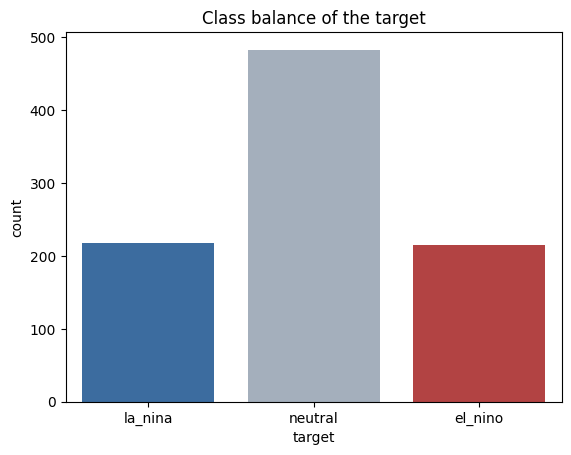

In [11]:
sns.countplot (x=y, order=['la_nina', 'neutral', 'el_nino'], palette=['#2b6cb0', '#a0aec0', '#c53030'])
plt.title('Class balance of the target'); plt.show()

3. **Train/test split**
This is a time series, so i split by time, not at random. A random split would let the model ''see the future'':neighbouring seasons are very similar, which would inflate the scores.

Training set: 1950 to 2015
Test set: 2016 to present


In [12]:
train = data['year'] <=2015
x_train, x_test = x[train], x[~train]
y_train, y_test = y[train], y[~train]
print ('Training rows:', len(x_train), '| Test rows:', len(x_test))
print ('Test class counts:'); print (y_test.value_counts())


Training rows: 789 | Test rows: 126
Test class counts:
target
neutral    65
el_nino    31
la_nina    30
Name: count, dtype: int64


4. **Train two supervised models**


*   Logistic Regression: a simple, interpretable linear model. Features are scaled first because logistic regresssion is sensitive to feature scale.
*   Random Forest Classifier: an ensemble of decisionn trees that can capture non-linear patternns and feature interactions.



In [14]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight='balanced'))
rf = RandomForestClassifier(n_estimators=300, max_depth=6, class_weight='balanced', random_state=42)

log_reg.fit(x_train, y_train)
rf.fit(x_train, y_train)
print('Both models trained.')

Both models trained.


5. **Predictions on the test data**

In [15]:
pred_lr = log_reg.predict(x_test)
pred_rf = rf.predict(x_test)

preview = data.loc[~train, ['year', 'season', 'anom_c']].copy()
preview['actual_next'] = y_test.values
preview['logistic_reg'] = pred_lr
preview['random_forest'] = pred_rf
preview.head(15)

,year,season,anom_c,actual_next,logistic_reg,random_forest
792,2016,DJF,2.50,el_nino,el_nino,el_nino
793,2016,JFM,2.21,el_nino,el_nino,el_nino
794,2016,FMA,1.69,el_nino,el_nino,el_nino
795,2016,MAM,1.11,el_nino,el_nino,el_nino
796,2016,AMJ,0.57,neutral,neutral,neutral
797,2016,MJJ,0.09,neutral,neutral,neutral
798,2016,JJA,-0.19,neutral,neutral,neutral
799,2016,JAS,-0.34,neutral,neutral,neutral
800,2016,ASO,-0.42,neutral,neutral,neutral
801,2016,SON,-0.51,neutral,la_nina,la_nina


6. **Evaluation**


*   Accuracy: share of all predictions that are correct.
*   Precision: of the seasons predicted as a class, how many really were that class.
*   Recall: of the real seasons, how many the model caught.
*   F1 score: balance of precision and recall.
*   Confusion matrix: shows which phases get mixed up.








In [16]:
labels = ['la_nina', 'neutral', 'el_nino']
def evaluate(name, pred):
    return {'Model': name,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision (macro)': precision_score(y_test, pred, average='macro', zero_division=0),
            'Recall (macro)': recall_score(y_test, pred, average='macro', zero_division=0),
            'F1 (macro)': f1_score(y_test, pred, average='macro', zero_division=0)}
results = pd.DataFrame([evaluate('Logistic Regression', pred_lr),
                        evaluate('Random Forest', pred_rf)]).set_index('Model').round(3)
results

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
Logistic Regression,0.905,0.892,0.927,0.906
Random Forest,0.889,0.880,0.899,0.889


In [17]:
print ('=== Logistic Regression ===')
print (classification_report(y_test, pred_lr, labels=labels, zero_division=0))
print ('=== Random Forest ===')
print (classification_report(y_test, pred_rf, labels=labels, zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

     la_nina       0.83      1.00      0.91        30
     neutral       0.96      0.85      0.90        65
     el_nino       0.88      0.94      0.91        31

    accuracy                           0.90       126
   macro avg       0.89      0.93      0.91       126
weighted avg       0.91      0.90      0.90       126

=== Random Forest ===
              precision    recall  f1-score   support

     la_nina       0.84      0.90      0.87        30
     neutral       0.92      0.86      0.89        65
     el_nino       0.88      0.94      0.91        31

    accuracy                           0.89       126
   macro avg       0.88      0.90      0.89       126
weighted avg       0.89      0.89      0.89       126



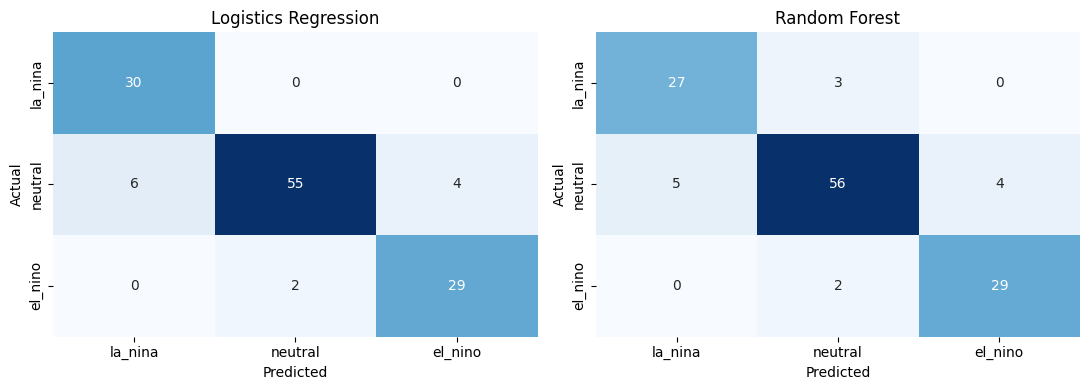

In [23]:
fig, axes = plt.subplots(1,2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, [('Logistics Regression', pred_lr), ('Random Forest', pred_rf)]):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(name); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout(); plt.show()

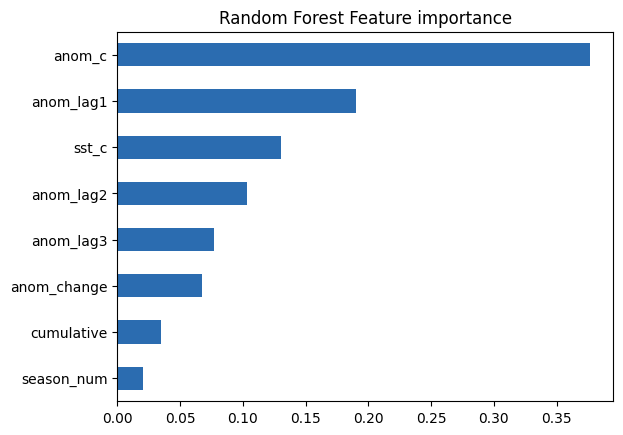

In [24]:
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', color='#2b6cb0'); plt.title('Random Forest Feature importance'); plt.show()

7. **Comparison and discussion**
Logistic regresssion did better than Random Forest. It was correct about 90% of the time, and its macro F1 was about 0.91 versus 0.87.

**Catching El Nino and La nina events**. Both models caught El nino well (recall 0.94). Logistic Regression caught every La nina season in the test period (recall 1.00) against 0.90 for the Random Forest.

The ENSO phase is defined by thresholds on the temperature anomaly, so the relationship between the current/lagged anomaly and next season's phase is closer to linear. Logistic Regression captures this well.